# TA-06 Pemodelan dan Simulasi — Sistem Dinamik Penurunan Suhu Kopi Panas

**Modul 6: Dynamic System Modelling**

Notebook ini memodelkan secangkir kopi panas yang mendingin di udara ruang, dengan tambahan
*mug warmer* (pemanas listrik di bawah cangkir) sebagai sinyal kontrol.

Model (neraca energi, lumped / ODE orde-1):

$$m\,c\,\frac{dT}{dt} = u(t) - hA\,\big(T - T_\infty\big)$$

| Simbol | Arti | Nilai |
|---|---|---|
| $m$ | massa kopi (250 mL) | 0,25 kg |
| $c$ | kalor jenis kopi (≈ air) | 4180 J/(kg·K) |
| $h$ | koefisien perpindahan panas gabungan | 12 W/(m²·K) |
| $A$ | luas permukaan pelepas panas | 0,03 m² |
| $T_\infty$ | suhu ruang | 25 °C |
| $T_0$ | suhu awal kopi | 90 °C |
| $u(t)$ | daya pemanas (sinyal kontrol) | W |
| $\Delta t$ | langkah waktu Euler | 1 s |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs('gambar', exist_ok=True)   # folder untuk menyimpan grafik

# ---------------- Parameter sistem ----------------
m     = 0.25      # kg   (250 mL kopi)
c     = 4180      # J/(kg.K)
h     = 12        # W/(m2.K)
A     = 0.03      # m2
T_env = 25.0      # degC  suhu ruang
T0    = 90.0      # degC  suhu awal kopi

hA = h * A                 # W/K
mc = m * c                 # J/K  (kapasitas panas)
k  = hA / mc               # 1/s  konstanta pendinginan
tau = 1 / k                # s    konstanta waktu

print(f"hA  = {hA:.2f} W/K")
print(f"mc  = {mc:.0f} J/K")
print(f"k   = {k:.4e} 1/s  = {k*60:.5f} 1/menit")
print(f"tau = {tau:.0f} s  = {tau/60:.1f} menit")

hA  = 0.36 W/K
mc  = 1045 J/K
k   = 3.4450e-04 1/s  = 0.02067 1/menit
tau = 2903 s  = 48.4 menit


## 1. Verifikasi perhitungan manual (Euler, Δt = 60 s)

$T_{n+1} = T_n + \Delta t\cdot\left[-k\,(T_n - T_\infty)\right]$ dibandingkan dengan solusi analitik
$T(t) = T_\infty + (T_0 - T_\infty)\,e^{-kt}$.

In [2]:
dt_manual = 60
T = T0
print(f"{'n':>2} {'t(menit)':>8} {'T_n(C)':>9} {'T_n-Tenv':>9} {'dT/dt(C/s)':>11} {'T_n+1(C)':>9} {'Analitik':>9}")
for n in range(6):
    dTdt = -k * (T - T_env)
    T_next = T + dTdt * dt_manual
    T_exact = T_env + (T0 - T_env) * np.exp(-k * n * dt_manual)
    print(f"{n:>2} {n:>8} {T:>9.4f} {T-T_env:>9.4f} {dTdt:>11.6f} {T_next:>9.4f} {T_exact:>9.4f}")
    T = T_next

t60 = np.log((T0 - T_env) / (60 - T_env)) / k
print(f"\nWaktu sampai kopi 60 C (analitik): {t60:.0f} s = {t60/60:.1f} menit")
print(f"Daya pemanas agar steady di 60 C : {hA*(60-T_env):.1f} W")

 n t(menit)    T_n(C)  T_n-Tenv  dT/dt(C/s)  T_n+1(C)  Analitik
 0        0   90.0000   65.0000   -0.022392   88.6565   90.0000
 1        1   88.6565   63.6565   -0.021929   87.3407   88.6702
 2        2   87.3407   62.3407   -0.021476   86.0521   87.3677
 3        3   86.0521   61.0521   -0.021032   84.7902   86.0918
 4        4   84.7902   59.7902   -0.020598   83.5543   84.8420
 5        5   83.5543   58.5543   -0.020172   82.3440   83.6178

Waktu sampai kopi 60 C (analitik): 1797 s = 29.9 menit
Daya pemanas agar steady di 60 C : 12.6 W


## 2. Fungsi simulasi (metode Euler)

Fungsi umum: sinyal kontrol `u(t)` dan suhu ruang `Tenv(t)` dapat berupa fungsi waktu,
sehingga satu fungsi dipakai untuk semua skenario (steady state, step, impulse, ramp, sinus, gangguan).

In [3]:
def simulasi(u_func, T_awal=T0, t_end=120*60, dt=1.0, Tenv_func=None):
    # Simulasi m*c*dT/dt = u(t) - hA*(T - Tenv) dengan metode Euler.
    if Tenv_func is None:
        Tenv_func = lambda t: T_env
    t = np.arange(0, t_end + dt, dt)
    T = np.zeros(len(t), dtype=float)     # dtype float (bukan int)
    u = np.array([u_func(ti) for ti in t], dtype=float)
    T[0] = T_awal
    for i in range(1, len(t)):
        dTdt = (u[i-1] - hA * (T[i-1] - Tenv_func(t[i-1]))) / mc
        T[i] = T[i-1] + dTdt * dt
    return t, T, u

def plot_respon(t, T, u, judul, nama_file, garis=None, tampil_env=True,
                label_bawah='Daya pemanas u(t) (W)'):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                                   gridspec_kw={'height_ratios': [2, 1]})
    ax1.plot(t/60, T, color='tab:red', lw=2, label='Suhu kopi T(t)')
    if tampil_env:
        ax1.axhline(T_env, color='gray', ls=':', label='Suhu ruang 25 °C')
    if garis is not None:
        ax1.axhline(garis, color='tab:orange', ls='--', label=f'Acuan {garis:.0f} °C')
    ax1.set_ylabel('Suhu (°C)'); ax1.set_title(judul); ax1.grid(True, alpha=.4); ax1.legend()
    ax2.plot(t/60, u, color='tab:blue', ls='--', lw=2)
    ax2.set_ylabel(label_bawah); ax2.set_xlabel('Waktu (menit)'); ax2.grid(True, alpha=.4)
    plt.tight_layout()
    plt.savefig(f'gambar/{nama_file}.png', dpi=150)
    plt.show()

## 3. Simulasi dasar — kopi mendingin tanpa pemanas (u = 0)

t =   0 menit : T =  90.00 C (analitik  90.00 C)
t =  10 menit : T =  77.86 C (analitik  77.86 C)
t =  30 menit : T =  59.96 C (analitik  59.96 C)
t =  60 menit : T =  43.80 C (analitik  43.81 C)
t = 120 menit : T =  30.44 C (analitik  30.44 C)
Galat maksimum Euler vs analitik: 0.0041 C


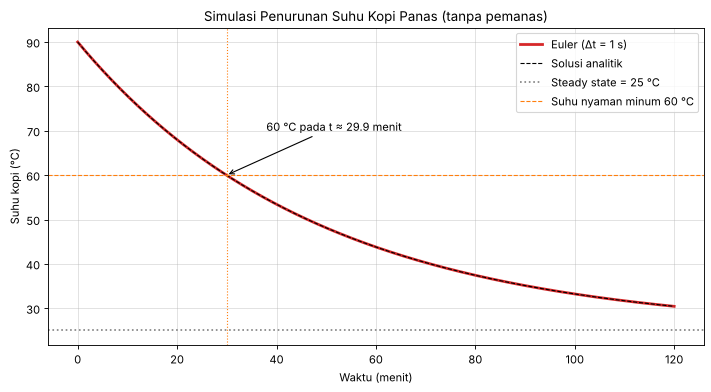

In [4]:
t, T, u = simulasi(lambda t: 0.0)
T_analitik = T_env + (T0 - T_env) * np.exp(-k * t)

plt.figure(figsize=(9, 5))
plt.plot(t/60, T, color='tab:red', lw=2.5, label='Euler (Δt = 1 s)')
plt.plot(t/60, T_analitik, 'k--', lw=1, label='Solusi analitik')
plt.axhline(T_env, color='gray', ls=':', label='Steady state = 25 °C')
plt.axhline(60, color='tab:orange', ls='--', lw=1, label='Suhu nyaman minum 60 °C')
plt.axvline(t60/60, color='tab:orange', ls=':', lw=1)
plt.annotate(f'60 °C pada t ≈ {t60/60:.1f} menit', xy=(t60/60, 60), xytext=(t60/60+8, 70),
             arrowprops=dict(arrowstyle='->'))
plt.xlabel('Waktu (menit)'); plt.ylabel('Suhu kopi (°C)')
plt.title('Simulasi Penurunan Suhu Kopi Panas (tanpa pemanas)')
plt.legend(); plt.grid(True, alpha=.4); plt.tight_layout()
plt.savefig('gambar/01_pendinginan_dasar.png', dpi=150)
plt.show()

for menit in [0, 10, 30, 60, 120]:
    i = menit * 60
    print(f"t = {menit:>3} menit : T = {T[i]:6.2f} C (analitik {T_analitik[i]:6.2f} C)")
print(f"Galat maksimum Euler vs analitik: {np.max(np.abs(T - T_analitik)):.4f} C")

## 4. Simulasi steady state

Steady state: $dT/dt = 0 \Rightarrow T_{ss} = T_\infty + u/(hA)$.
* Tanpa pemanas ($u = 0$): $T_{ss} = 25$ °C.
* Dengan pemanas $u = 12{,}6$ W: $T_{ss} = 25 + 12{,}6/0{,}36 = 60$ °C.

u_ss = 12.60 W
T akhir kasus A = 25.000 C, kasus B = 60.000 C, kasus C (300 menit) = 60.061 C


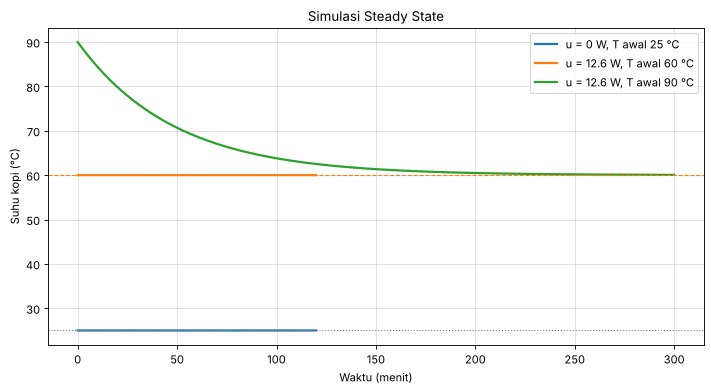

In [5]:
u_ss = hA * (60 - T_env)
tA, TA, _ = simulasi(lambda t: 0.0, T_awal=T_env)            # mulai di 25 C, u = 0
tB, TB, _ = simulasi(lambda t: u_ss, T_awal=60.0)            # mulai di 60 C, u = 12.6 W
tC, TC, _ = simulasi(lambda t: u_ss, T_awal=T0, t_end=300*60)  # mulai 90 C, u = 12.6 W

plt.figure(figsize=(9, 5))
plt.plot(tA/60, TA, lw=2, label='u = 0 W, T awal 25 °C')
plt.plot(tB/60, TB, lw=2, label=f'u = {u_ss:.1f} W, T awal 60 °C')
plt.plot(tC/60, TC, lw=2, label=f'u = {u_ss:.1f} W, T awal 90 °C')
plt.axhline(60, color='tab:orange', ls='--', lw=1)
plt.axhline(T_env, color='gray', ls=':', lw=1)
plt.xlabel('Waktu (menit)'); plt.ylabel('Suhu kopi (°C)')
plt.title('Simulasi Steady State')
plt.legend(); plt.grid(True, alpha=.4); plt.tight_layout()
plt.savefig('gambar/02_steady_state.png', dpi=150)
plt.show()
print(f"u_ss = {u_ss:.2f} W")
print(f"T akhir kasus A = {TA[-1]:.3f} C, kasus B = {TB[-1]:.3f} C, kasus C (300 menit) = {TC[-1]:.3f} C")

## 5. Respon terhadap sinyal kontrol

### 5a. Sinyal step — pemanas dinyalakan 12,6 W pada menit ke-20

T saat pemanas menyala (20 menit) = 67.99 C
T pada 180 menit                 = 60.29 C


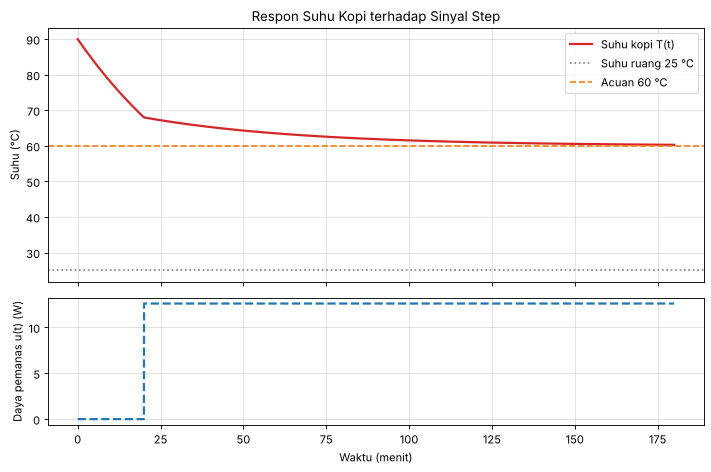

In [6]:
u_step = lambda t: u_ss if t >= 20*60 else 0.0
t, T_step, u = simulasi(u_step, t_end=180*60)
plot_respon(t, T_step, u, 'Respon Suhu Kopi terhadap Sinyal Step', '03_step', garis=60)
print(f"T saat pemanas menyala (20 menit) = {T_step[20*60]:.2f} C")
print(f"T pada 180 menit                 = {T_step[-1]:.2f} C")

### 5b. Sinyal impulse — dipanaskan singkat 600 W selama 10 s pada menit ke-30
(seperti memanaskan sebentar di microwave; energi = 6000 J)

Lonjakan suhu teoretis = 6000 J / 1045 J/K = 5.74 C
T sebelum impuls = 59.96 C, sesudah = 65.57 C
Selisih dg tanpa impuls pada 120 menit = 0.89 C


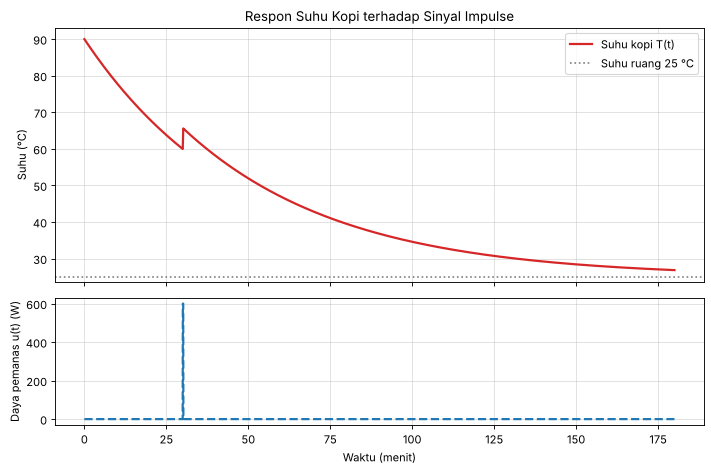

In [7]:
u_imp = lambda t: 600.0 if 30*60 <= t < 30*60 + 10 else 0.0
t, T_imp, u = simulasi(u_imp, t_end=180*60)
t_, T_tanpa, _ = simulasi(lambda t: 0.0, t_end=180*60)
plot_respon(t, T_imp, u, 'Respon Suhu Kopi terhadap Sinyal Impulse', '04_impulse')
i0 = 30*60
print(f"Lonjakan suhu teoretis = 6000 J / {mc:.0f} J/K = {6000/mc:.2f} C")
print(f"T sebelum impuls = {T_imp[i0]:.2f} C, sesudah = {T_imp[i0+10]:.2f} C")
print(f"Selisih dg tanpa impuls pada 120 menit = {T_imp[120*60]-T_tanpa[120*60]:.2f} C")

### 5c. Sinyal ramp — daya pemanas naik 0,1 W/menit mulai menit ke-10

Suhu minimum = 46.45 C pada t = 87.2 menit
Pada 180 menit: u = 17.0 W, T = 60.76 C


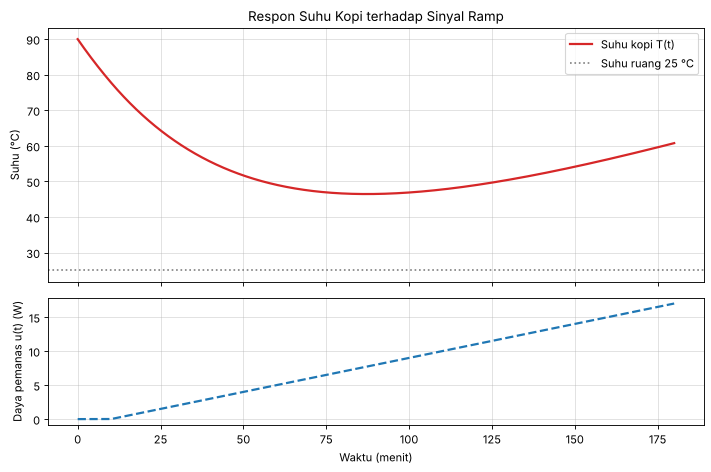

In [8]:
r = 0.1 / 60     # W per detik
u_ramp = lambda t: r * (t - 10*60) if t >= 10*60 else 0.0
t, T_ramp, u = simulasi(u_ramp, t_end=180*60)
plot_respon(t, T_ramp, u, 'Respon Suhu Kopi terhadap Sinyal Ramp', '05_ramp')
idx = np.argmin(T_ramp)
print(f"Suhu minimum = {T_ramp[idx]:.2f} C pada t = {t[idx]/60:.1f} menit")
print(f"Pada 180 menit: u = {u[-1]:.1f} W, T = {T_ramp[-1]:.2f} C")

### 5d. Sinyal sinusoida — $u(t) = 12{,}6 + 6\sin(2\pi t / 20\ \text{menit})$ W

Amplitudo suhu teori    = 1.09 C, tertinggal fase 86 derajat
Amplitudo suhu simulasi = 1.11 C (rata-rata 60.02 C)


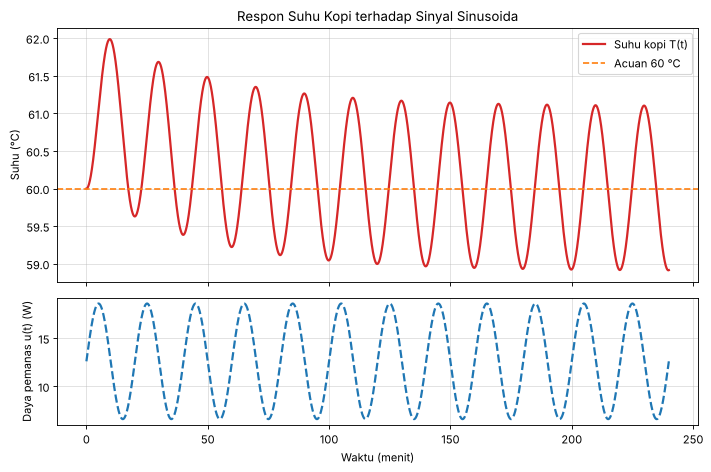

In [9]:
P = 20 * 60                         # periode 20 menit
w = 2 * np.pi / P
u_sin = lambda t: u_ss + 6 * np.sin(w * t)
t, T_sin, u = simulasi(u_sin, T_awal=60.0, t_end=240*60)
plot_respon(t, T_sin, u, 'Respon Suhu Kopi terhadap Sinyal Sinusoida', '06_sinus', garis=60,
            tampil_env=False)

amp_teori = (6 / hA) / np.sqrt(1 + (w * tau)**2)
fasa = np.degrees(np.arctan(w * tau))
seg = T_sin[t >= 150*60]   # ambil setelah transien hilang
print(f"Amplitudo suhu teori    = {amp_teori:.2f} C, tertinggal fase {fasa:.0f} derajat")
print(f"Amplitudo suhu simulasi = {(seg.max()-seg.min())/2:.2f} C (rata-rata {seg.mean():.2f} C)")

## 6. Input gangguan (disturbance) — suhu ruang turun dari 25 °C ke 18 °C pada menit ke-40
Pemanas tetap 12,6 W (dirancang untuk 60 °C pada suhu ruang 25 °C).

Steady state baru teoretis = 18 + 12.6/0.36 = 53.0 C
T pada 240 menit (simulasi) = 53.11 C


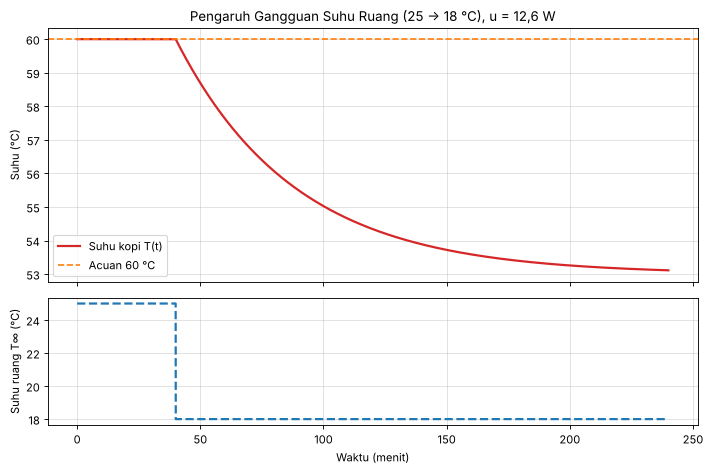

In [10]:
Tenv_gang = lambda t: 18.0 if t >= 40*60 else 25.0
t, T_g, u = simulasi(lambda t: u_ss, T_awal=60.0, t_end=240*60, Tenv_func=Tenv_gang)
T_ruang = np.array([Tenv_gang(ti) for ti in t])   # panel bawah: gangguan suhu ruang
plot_respon(t, T_g, T_ruang, 'Pengaruh Gangguan Suhu Ruang (25 → 18 °C), u = 12,6 W',
            '07_gangguan', garis=60, tampil_env=False, label_bawah='Suhu ruang T∞ (°C)')
print(f"Steady state baru teoretis = 18 + {u_ss:.1f}/{hA} = {18 + u_ss/hA:.1f} C")
print(f"T pada 240 menit (simulasi) = {T_g[-1]:.2f} C")

## 7. Perbandingan semua sinyal kontrol

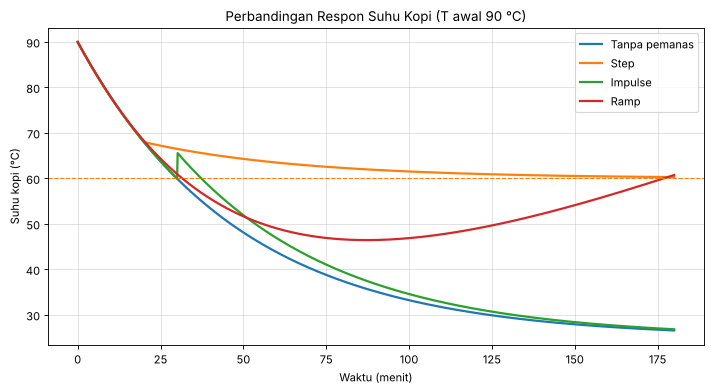

In [11]:
plt.figure(figsize=(9, 5))
t_all = np.arange(0, 180*60 + 1, 1)
for nama, T_ in [('Tanpa pemanas', T_tanpa), ('Step', T_step),
                 ('Impulse', T_imp), ('Ramp', T_ramp)]:
    plt.plot(t_all/60, T_, lw=2, label=nama)
plt.axhline(60, color='tab:orange', ls='--', lw=1)
plt.xlabel('Waktu (menit)'); plt.ylabel('Suhu kopi (°C)')
plt.title('Perbandingan Respon Suhu Kopi (T awal 90 °C)')
plt.legend(); plt.grid(True, alpha=.4); plt.tight_layout()
plt.savefig('gambar/08_perbandingan.png', dpi=150)
plt.show()